# iAmTime forecasting demo on Walmart sales

[iAmTime](https://arxiv.org/abs/2603.22586) is a time-series foundation model that accepts **in-context examples**: completed (history → future) demonstrations passed together with the series to forecast. This notebook demonstrates four forecasting workflows on the public Walmart weekly-sales dataset, each in the same three-part format:

| Part | What you get |
|---|---|
| **Input card** | the exact array / dict shape passed to `predict_quantiles` |
| **Hero figure** | history → forecast fan (10–90 %) + median, observed future overlaid, and one **dashed reference line** = "what you would get without the feature" |
| **Honesty table** | the same comparison on 64–512 random series: mean / median MASE, win rate, paired bootstrap CI |

| § | Task | Reference line | Takeaway |
|---|---|---|---|
| 1 | Univariate forecasting | seasonal naive | zero-shot fan chart; beats the analyst's baseline |
| 2 | Multivariate forecasting | univariate forecast of the same variate | joint context helps correlated departments, not uniformly |
| 3 | Exogenous variables and promotions | forecast without covariates / without future promotions | covariates are *inputs*, so "what-if" is a batch of scenarios; dose–response curve |
| 4 | Forecasting with examples (ICL) | zero-shot from the same 104-week history | examples **substitute for missing history** (cold start); with a full two-year history they add little, and a shuffled-futures control shows the model really reads the demonstrated history → future mapping |

Data: `autogluon/fev_datasets`, configuration `walmart`: one weekly series of department sales per `(Store, Dept)` pair with 10 exogenous channels. Checkpoint: [`anishsaha/iAmTime-base-forecast`](https://huggingface.co/anishsaha/iAmTime-base-forecast).

> Cells marked **▶ new** were added to the original usage notebook. All outputs are from a CPU run. Figures are saved to `docs/figures/` (relative to the notebook) for the README.

## Setup

Install the package with the notebook and training extras from the repository root. The `training` extra provides `datasets` and `pandas`, which this notebook uses to load the Walmart data:

```bash
pip install -e ".[notebook,training]"
```

The first run downloads the checkpoint and the dataset from the Hugging Face Hub and caches them locally.

In [1]:
from datetime import timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from matplotlib.ticker import FuncFormatter
from sklearn.cluster import KMeans

from iAmTime.pipeline import iAmTimePipeline

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=3, suppress=True)

In [2]:
if torch.cuda.is_available():
    DEVICE = "cuda"
    TORCH_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32
else:
    DEVICE = "cpu"
    TORCH_DTYPE = torch.float32

MODEL_ID = "anishsaha/iAmTime-base-forecast"

print(f"Device: {DEVICE}")
print(f"Dtype: {TORCH_DTYPE}")
print(f"Model: {MODEL_ID}")

Device: cpu
Dtype: torch.float32
Model: anishsaha/iAmTime-base-forecast


In [3]:
pipeline = iAmTimePipeline.from_pretrained(
    MODEL_ID,
    device_map=DEVICE,
    dtype=TORCH_DTYPE,
)
pipeline.model.eval()
print("Pipeline loaded successfully.")

Pipeline loaded successfully.


## Walmart data

Each item is a `(Store, Dept)` weekly sales series from 2010-02-05 to 2012-10-26 (143 weeks), with 10 exogenous channels that share the item's timestamps:

- `IsHoliday`: the week contains the Super Bowl, Labor Day, Thanksgiving, or Christmas.
- `Temperature`, `Fuel_Price`, `CPI`, `Unemployment`: regional weather and economic indicators for the store.
- `MarkDown1` to `MarkDown5`: anonymised promotional markdowns. They are only recorded from November 2011, so earlier values are `NaN`. The pipeline treats `NaN` as missing.

As in the Walmart evaluation notebook, the last `HORIZON = 39` weeks (about nine months) of every series are held out as ground truth. The model sees only the first 104 weeks.

In [4]:
DATASET_PATH = "autogluon/fev_datasets"
DATASET_CONFIG = "walmart"
SERIES_LENGTH = 143
HORIZON = 39  # Weeks held out as ground truth.
HISTORY = SERIES_LENGTH - HORIZON
COVARIATES = [
    "IsHoliday", "Temperature", "Fuel_Price", "CPI", "Unemployment",
    "MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5",
]

walmart = load_dataset(DATASET_PATH, DATASET_CONFIG)["train"].to_pandas().set_index("id")
walmart = walmart[walmart["target"].apply(len) == SERIES_LENGTH]  # Keep complete series only.
dates = pd.DatetimeIndex(walmart["timestamp"].iloc[0])
assert all((pd.DatetimeIndex(ts) == dates).all() for ts in walmart["timestamp"])
history_dates, future_dates = dates[:HISTORY], dates[HISTORY:]

def series(item_id, column="target"):
    return np.asarray(walmart.loc[item_id, column], dtype=np.float32)

print(f"{len(walmart)} complete series, {walmart['Store'].nunique()} stores, {walmart['Dept'].nunique()} departments")
print(f"History: {history_dates[0].date()} to {history_dates[-1].date()} ({HISTORY} weeks)")
print(f"Horizon: {future_dates[0].date()} to {future_dates[-1].date()} ({HORIZON} weeks)")

2842 complete series, 45 stores, 74 departments
History: 2010-02-05 to 2012-01-27 (104 weeks)
Horizon: 2012-02-03 to 2012-10-26 (39 weeks)


### Forecast output and evaluation

`predict_quantiles` returns quantiles with shape `(batch, horizon, quantiles)` for univariate input and `(batch, variates, horizon, quantiles)` for uniform multivariate input. This notebook requests the 10th, 50th, and 90th percentiles.

Forecasts are scored with **MASE**: the mean absolute error of the median forecast divided by the in-sample mean absolute error of a one-step naive forecast on the history. Lower is better; 1.0 means "as good as repeating last week".

Every section ends with a **scorecard**: the same comparison on many random series, reported as mean and median MASE, the win rate against a reference variant, and a paired bootstrap 95 % CI on the mean difference. The scorecard is what tells you whether the chosen illustration generalises.

In [5]:
QUANTILE_LEVELS = [0.1, 0.5, 0.9]
COLORS = {"history": "#3f4652", "truth": "#23836b", "forecast": "#8f5fa2", "reference": "#d08c2e"}
HOLIDAY_COLOR = "#377ca8"
HALF_WEEK = timedelta(days=3.5)  # Weekly points sit mid-bar; boundaries are half a week away.

def predict(input_batch, horizon=HORIZON):
    quantiles, _ = pipeline.predict_quantiles(
        input_batch,
        prediction_length=horizon,
        quantile_levels=QUANTILE_LEVELS,
    )
    return quantiles.detach().cpu().numpy() if isinstance(quantiles, torch.Tensor) else quantiles

def mase(history, truth, forecast):
    return float(np.mean(np.abs(truth - forecast)) / np.mean(np.abs(np.diff(history))))

def describe(item_id):
    store, dept = item_id.split("_")
    return f"Store {store}, dept {dept}"

sales_formatter = FuncFormatter(lambda value, _: f"{value / 1000:,.0f}k")

def plot_forecast(ax, history, truth, quantiles, title, reference=None, reference_label=None):
    ax.plot(history_dates[-len(history):], history, color=COLORS["history"], lw=1.3, label="History")
    ax.plot(future_dates, truth, color=COLORS["truth"], lw=1.5, label="Observed future")
    ax.fill_between(future_dates, quantiles[:, 0], quantiles[:, 2], color=COLORS["forecast"], alpha=0.20, label="10-90% interval")
    ax.plot(future_dates, quantiles[:, 1], color=COLORS["forecast"], lw=1.8, label="Median forecast")
    if reference is not None:
        ax.plot(future_dates, reference, color=COLORS["reference"], lw=1.3, ls="--", label=reference_label)
    ax.axvline(future_dates[0] - HALF_WEEK, color="#999999", lw=0.8, ls="--")
    ax.yaxis.set_major_formatter(sales_formatter)
    ax.set_title(title)
    ax.set_ylabel("Weekly sales")

In [6]:
# ▶ new: scorecard, seasonal-naive baseline, figure export.
from pathlib import Path

FIG_DIR = Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

def seasonal_naive(history, horizon=HORIZON, season=52):
    # Same week last year; falls back to repeating the last season if the horizon is longer than one season.
    last_season = history[-season:]
    return np.resize(last_season, horizon)

def scorecard(scores, reference, n_boot=2000, seed=0):
    # scores: DataFrame, one column per variant, one row per series, values = MASE.
    rng = np.random.default_rng(seed)
    n = len(scores)
    idx = rng.integers(0, n, size=(n_boot, n))
    ref = scores[reference].to_numpy()
    rows = []
    for name in scores.columns:
        s = scores[name].to_numpy()
        diff = s - ref
        mean_ci = np.percentile(s[idx].mean(axis=1), [2.5, 97.5])
        diff_ci = np.percentile(diff[idx].mean(axis=1), [2.5, 97.5])
        rows.append({
            "mean MASE": s.mean(), "mean 95% CI": f"[{mean_ci[0]:.3f}, {mean_ci[1]:.3f}]",
            "median MASE": np.median(s),
            "win rate vs ref": np.nan if name == reference else (s < ref).mean(),
            "Δ mean vs ref": diff.mean(), "Δ 95% CI": f"[{diff_ci[0]:.3f}, {diff_ci[1]:.3f}]",
        })
    table = pd.DataFrame(rows, index=scores.columns)
    table.index.name = f"reference: {reference}"
    return table.round(3)

def plot_ladder(scores, reference, title, name=None, n_boot=2000):
    # Horizontal bars of mean MASE with bootstrap CIs; the reference bar is drawn in grey.
    rng = np.random.default_rng(0)
    idx = rng.integers(0, len(scores), size=(n_boot, len(scores)))
    means = scores.mean()
    cis = np.stack([np.percentile(scores[c].to_numpy()[idx].mean(axis=1), [2.5, 97.5]) for c in scores.columns])
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(scores.columns) + 1.2))
    y = np.arange(len(scores.columns))[::-1]
    colors = ["#9a9a9a" if c == reference else COLORS["forecast"] for c in scores.columns]
    ax.barh(y, means, color=colors, height=0.6)
    ax.errorbar(means, y, xerr=[means - cis[:, 0], cis[:, 1] - means], fmt="none", ecolor="#333333", capsize=3, lw=1)
    ax.set_yticks(y, scores.columns)
    ax.set_xlabel(f"mean MASE over {len(scores)} series (bootstrap 95% CI)")
    ax.set_title(title)
    ax.axvline(means[reference], color="#9a9a9a", lw=0.8, ls="--")
    plt.tight_layout()
    if name:
        savefig(fig, name)
    plt.show()

## 1. Univariate forecasting

**Input card.** A two-dimensional array with shape `(batch, history)`:

```python
uni_input = np.stack([series("1_1"), series("1_92"), series("1_95")])[:, :HISTORY]   # (3, 104)
quantiles, _ = pipeline.predict_quantiles(uni_input, prediction_length=39, quantile_levels=[0.1, 0.5, 0.9])
# quantiles: (3, 39, 3)
```

The batch holds three departments of store 1 with different behaviour: department 1 has sharp holiday and spring peaks, department 92 a strong within-month cycle, and department 95 a slow seasonal swing. One call forecasts all three.

**How to read the figure.** Grey = the 104 weeks the model saw; the dashed vertical line is the forecast origin; purple = median forecast with the 10–90 % band; green = what actually happened. MASE in each title.

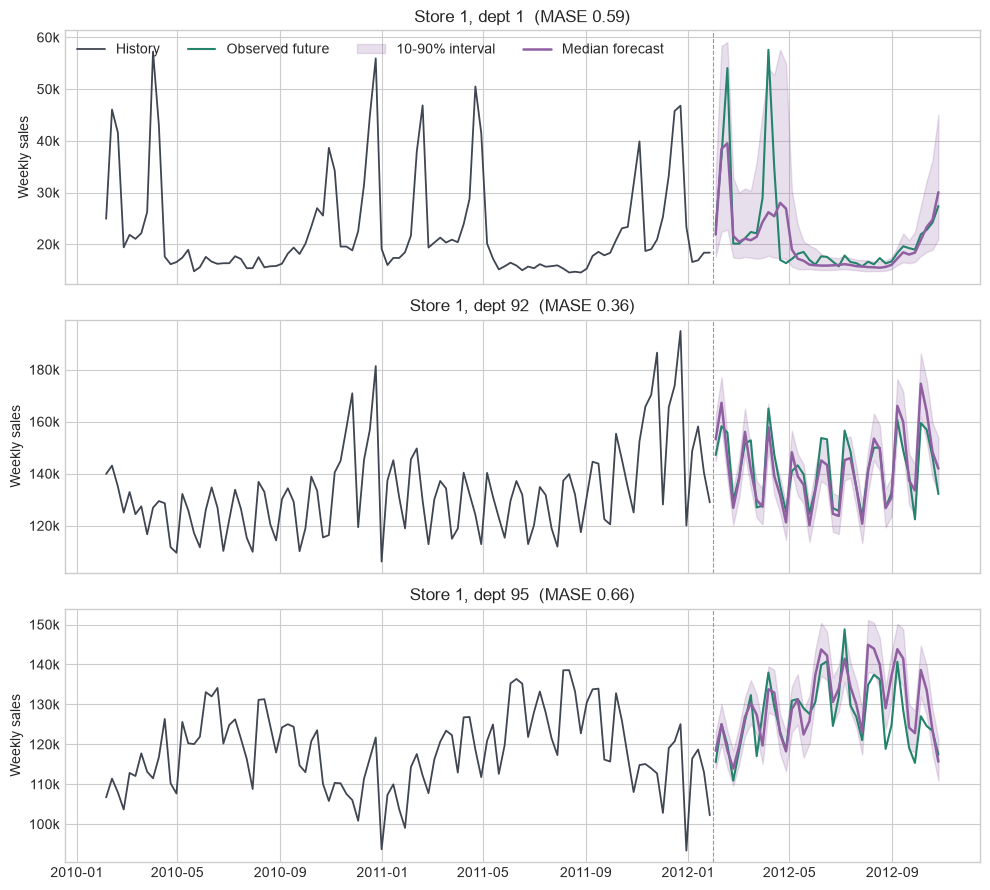

In [7]:
UNIVARIATE_IDS = ["1_1", "1_92", "1_95"]

uni_series = np.stack([series(item_id) for item_id in UNIVARIATE_IDS])
uni_input = uni_series[:, :HISTORY]  # (batch=3, history)
uni_quantiles = predict(uni_input)

fig, axes = plt.subplots(len(UNIVARIATE_IDS), 1, figsize=(10, 3.0 * len(UNIVARIATE_IDS)), sharex=True)
for ax, item_id, values, quantiles in zip(axes, UNIVARIATE_IDS, uni_series, uni_quantiles):
    score = mase(values[:HISTORY], values[HISTORY:], quantiles[:, 1])
    plot_forecast(ax, values[:HISTORY], values[HISTORY:], quantiles, f"{describe(item_id)}  (MASE {score:.2f})")
axes[0].legend(ncol=4, frameon=False, loc="upper left")
plt.tight_layout()
savefig(fig, "01_univariate")
plt.show()

### 1b. Scorecard: iAmTime vs. seasonal naive ▶ new

Zero-shot forecasts look impressive against nothing and credible against the baseline a retail analyst would actually use: **seasonal naive** (same week last year). 64 random complete series, fixed seed.

In [8]:
rng = np.random.default_rng(0)
complete_ids = walmart.index[walmart["target"].apply(lambda values: not np.isnan(values).any())]
sample_ids = rng.choice(complete_ids, size=64, replace=False)
sample_targets = np.stack([series(item_id) for item_id in sample_ids])

uni_sample_quantiles = predict(sample_targets[:, :HISTORY])
uni_scores = pd.DataFrame({
    "seasonal naive": [mase(y[:HISTORY], y[HISTORY:], seasonal_naive(y[:HISTORY])) for y in sample_targets],
    "iAmTime zero-shot": [mase(y[:HISTORY], y[HISTORY:], q[:, 1]) for y, q in zip(sample_targets, uni_sample_quantiles)],
}, index=sample_ids)
scorecard(uni_scores, reference="seasonal naive")

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: seasonal naive,,,,,,
seasonal naive,0.956,"[0.834, 1.087]",0.883,NaN,0.000,"[0.000, 0.000]"
iAmTime zero-shot,0.799,"[0.684, 0.926]",0.722,0.844,-0.157,"[-0.232, -0.083]"


## 2. Multivariate forecasting

**Input card.** A three-dimensional array with shape `(batch, variates, history)`; the output gains a variate axis:

```python
multi_input = np.stack([series("8_23"), series("8_7"), series("8_82")])[None, :, :HISTORY]   # (1, 3, 104)
quantiles, _ = pipeline.predict_quantiles(multi_input, prediction_length=39, quantile_levels=[0.1, 0.5, 0.9])
# quantiles: (1, 3, 39, 3)
```

iAmTime forecasts every variate and uses the histories of the other variates as additional context. Departments 23, 7, and 82 of store 8 have highly correlated histories (matrix printed below), so their joint history is a natural multivariate input.

**How to read the figure.** Solid purple = joint forecast; **dashed orange = the same department forecast on its own**. The title shows both MASE values; the gap between the lines is what the other variates contributed.

This triple was **selected for the demo** because joint context improves all three departments. Section 2b shows how typical that is.

Correlation of the histories:
[[1.    0.891 0.847]
 [0.891 1.    0.895]
 [0.847 0.895 1.   ]]


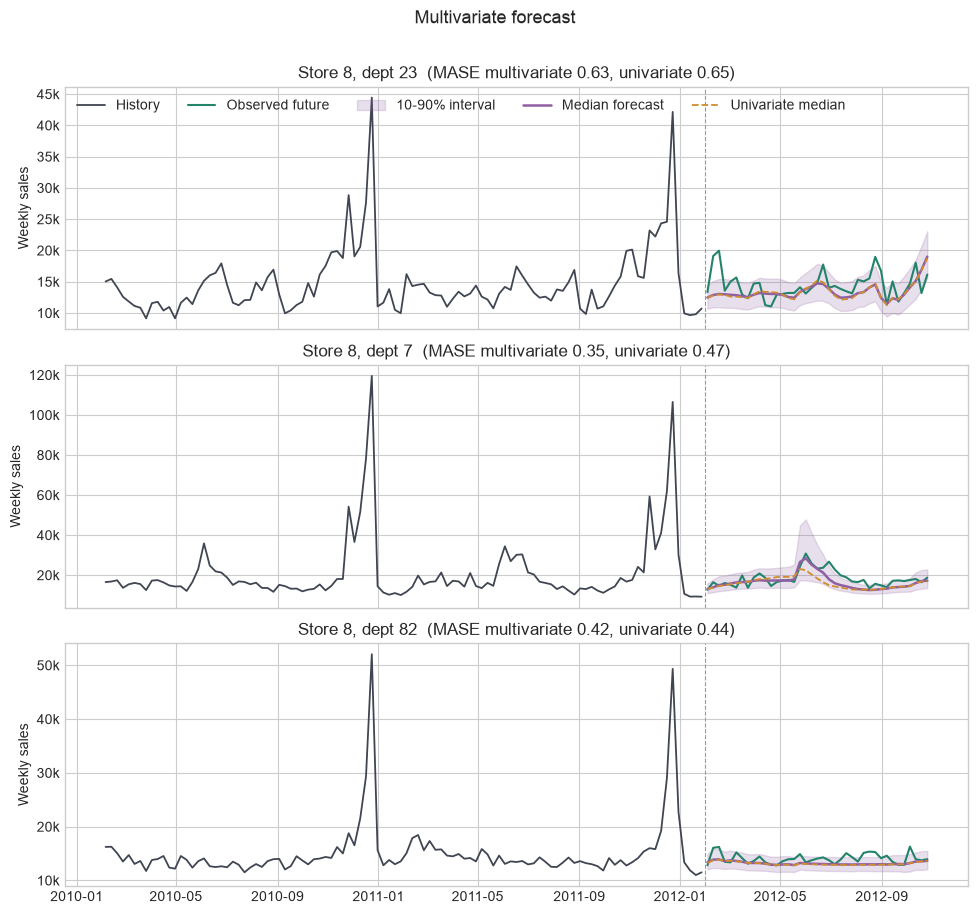

In [9]:
MULTIVARIATE_IDS = ["8_23", "8_7", "8_82"]

multi_series = np.stack([series(item_id) for item_id in MULTIVARIATE_IDS])
print("Correlation of the histories:")
print(np.corrcoef(multi_series[:, :HISTORY]))

multi_input = multi_series[None, :, :HISTORY]  # (batch=1, variates=3, history)
multi_quantiles = predict(multi_input)[0]
single_quantiles = predict(multi_series[:, :HISTORY])  # Each department on its own.

fig, axes = plt.subplots(len(MULTIVARIATE_IDS), 1, figsize=(10, 3.0 * len(MULTIVARIATE_IDS)), sharex=True)
for ax, item_id, values, quantiles, single in zip(axes, MULTIVARIATE_IDS, multi_series, multi_quantiles, single_quantiles):
    multi_score = mase(values[:HISTORY], values[HISTORY:], quantiles[:, 1])
    single_score = mase(values[:HISTORY], values[HISTORY:], single[:, 1])
    plot_forecast(ax, values[:HISTORY], values[HISTORY:], quantiles,
                  f"{describe(item_id)}  (MASE multivariate {multi_score:.2f}, univariate {single_score:.2f})",
                  reference=single[:, 1], reference_label="Univariate median")
axes[0].legend(ncol=5, frameon=False, loc="upper left")
fig.suptitle("Multivariate forecast", y=1.01, fontsize=13)
plt.tight_layout()
savefig(fig, "02_multivariate")
plt.show()

### 2b. Scorecard: joint vs. separate on 80 correlated triples ▶ new

For each of stores 1–20, take the 12 highest-volume departments, enumerate all triples, and keep the 4 with the highest mean pairwise correlation of their histories (80 triples, 240 variates). Every triple is forecast jointly and each variate separately.

In [10]:
from itertools import combinations

TRIPLE_STORES = range(1, 21)
TRIPLES_PER_STORE = 4
TOP_DEPARTMENTS = 12

triples = []
for store in TRIPLE_STORES:
    ids = [i for i in complete_ids if i.startswith(f"{store}_")]
    ids = sorted(ids, key=lambda i: -series(i)[:HISTORY].mean())[:TOP_DEPARTMENTS]
    hist = np.stack([series(i)[:HISTORY] for i in ids])
    corr = np.corrcoef(hist)
    scored = []
    for a, b, c in combinations(range(len(ids)), 3):
        scored.append(((corr[a, b] + corr[a, c] + corr[b, c]) / 3, (ids[a], ids[b], ids[c])))
    triples += [t for _, t in sorted(scored, reverse=True)[:TRIPLES_PER_STORE]]

triple_targets = np.stack([[series(i) for i in t] for t in triples])            # (80, 3, 143)
joint_quantiles = predict(triple_targets[:, :, :HISTORY])                        # (80, 3, 39, 3)
separate_quantiles = predict(triple_targets.reshape(-1, SERIES_LENGTH)[:, :HISTORY]).reshape(len(triples), 3, HORIZON, -1)

multi_scores = pd.DataFrame({
    "univariate (each variate alone)": [mase(y[:HISTORY], y[HISTORY:], q[:, 1]) for y, q in zip(triple_targets.reshape(-1, SERIES_LENGTH), separate_quantiles.reshape(-1, HORIZON, 3))],
    "multivariate (joint)": [mase(y[:HISTORY], y[HISTORY:], q[:, 1]) for y, q in zip(triple_targets.reshape(-1, SERIES_LENGTH), joint_quantiles.reshape(-1, HORIZON, 3))],
})
improved = (multi_scores["multivariate (joint)"] < multi_scores["univariate (each variate alone)"]).to_numpy().reshape(len(triples), 3)
print(f"All three variates improved in {improved.all(axis=1).sum()} of {len(triples)} triples; "
      f"at least one improved in {improved.any(axis=1).sum()}.")
scorecard(multi_scores, reference="univariate (each variate alone)")

All three variates improved in 22 of 80 triples; at least one improved in 75.


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: univariate (each variate alone),,,,,,
univariate (each variate alone),0.671,"[0.629, 0.713]",0.567,NaN,0.000,"[0.000, 0.000]"
multivariate (joint),0.652,"[0.611, 0.693]",0.542,0.646,-0.019,"[-0.028, -0.010]"


## 3. Forecasting with exogenous variables

**Input card.** A dictionary per series. Past covariates align with the target history; future covariates cover the forecast horizon. Covariates are named, so a batch can mix series with different covariate sets.

```python
{
    "target": series("1_72")[:HISTORY],                                        # (104,)
    "past_covariates":   {"IsHoliday": ..., "Temperature": ..., ...},          # each (104,)
    "future_covariates": {"IsHoliday": ..., "Temperature": ..., ...},          # each (39,)
}
```

This example passes all 10 native Walmart covariates for department 72 of store 1, a department with very large holiday peaks.

**How to read the figure.** Top panel: solid = forecast with covariates, **dashed = the same series without them**. Lower panels: the covariates over the full history and horizon (scaled to 0–1). Holiday weeks are shaded through every panel, so you can see a holiday line up with a peak in the target and with the solid line tracking it.

Caveat: the dataset provides the *observed* future covariates. Holidays are known in advance, but temperature, fuel price, CPI, unemployment, and markdowns would be forecasts or plans in a real deployment, so this setup is optimistic.

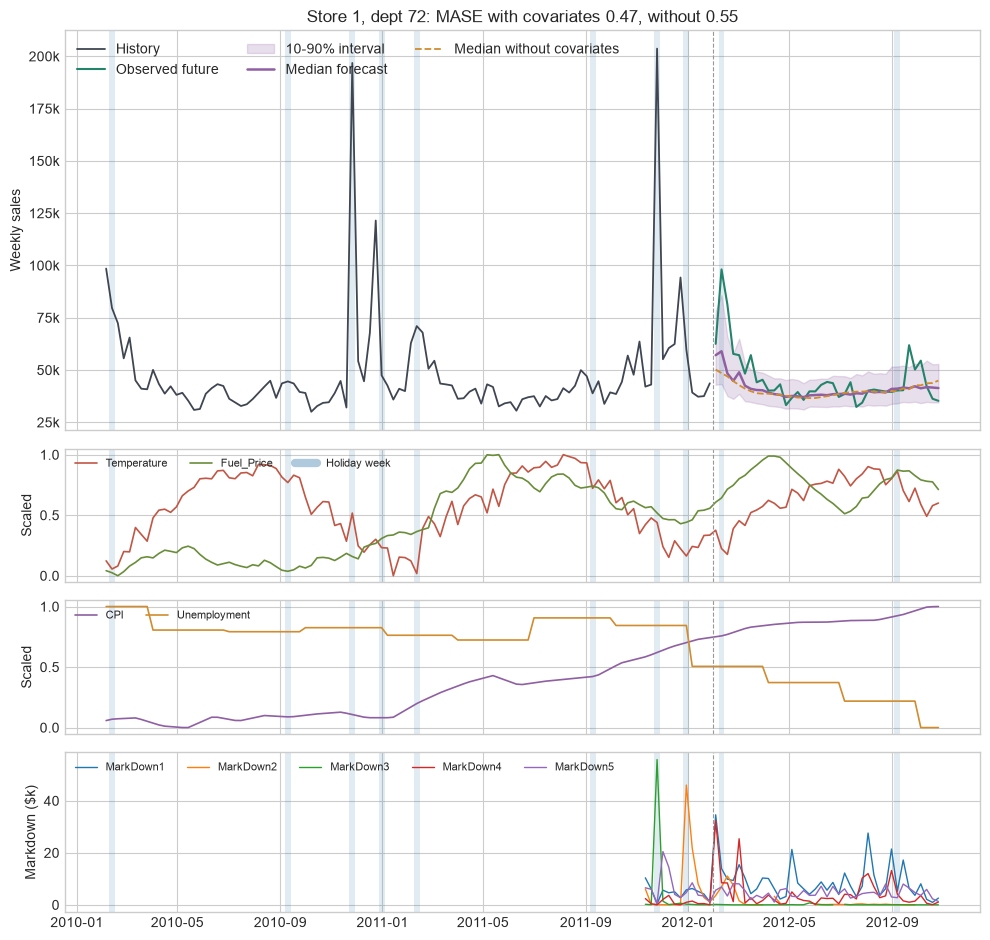

In [11]:
EXOG_ID = "1_72"

def make_covariate_input(item_id):
    covariates = {name: series(item_id, name) for name in COVARIATES}
    return {
        "target": series(item_id)[:HISTORY],
        "past_covariates": {name: values[:HISTORY] for name, values in covariates.items()},
        "future_covariates": {name: values[HISTORY:] for name, values in covariates.items()},
    }

exog_values = series(EXOG_ID)
exog_quantiles = predict([make_covariate_input(EXOG_ID)])[0]
no_exog_quantiles = predict(exog_values[None, :HISTORY])[0]
with_score = mase(exog_values[:HISTORY], exog_values[HISTORY:], exog_quantiles[:, 1])
without_score = mase(exog_values[:HISTORY], exog_values[HISTORY:], no_exog_quantiles[:, 1])

def scaled(values):
    return (values - np.nanmin(values)) / (np.nanmax(values) - np.nanmin(values))

def shade_holidays(ax):
    for week in np.flatnonzero(series(EXOG_ID, "IsHoliday")):
        ax.axvspan(dates[week] - HALF_WEEK, dates[week] + HALF_WEEK, color=HOLIDAY_COLOR, alpha=0.15, lw=0)

fig, axes = plt.subplots(4, 1, figsize=(10, 9.5), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1, 1.2]})
plot_forecast(axes[0], exog_values[:HISTORY], exog_values[HISTORY:], exog_quantiles,
              f"{describe(EXOG_ID)}: MASE with covariates {with_score:.2f}, without {without_score:.2f}",
              reference=no_exog_quantiles[:, 1], reference_label="Median without covariates")
axes[0].legend(ncol=3, frameon=False, loc="upper left")

for name, color in [("Temperature", "#c25645"), ("Fuel_Price", "#6a8d3a")]:
    axes[1].plot(dates, scaled(series(EXOG_ID, name)), color=color, lw=1.2, label=name)
for name, color in [("CPI", "#8f5fa2"), ("Unemployment", "#d08c2e")]:
    axes[2].plot(dates, scaled(series(EXOG_ID, name)), color=color, lw=1.2, label=name)
for index in range(1, 6):
    axes[3].plot(dates, series(EXOG_ID, f"MarkDown{index}") / 1000, lw=1.0, label=f"MarkDown{index}")
axes[1].set_ylabel("Scaled")
axes[2].set_ylabel("Scaled")
axes[3].set_ylabel("Markdown ($k)")
for ax in axes[1:]:
    ax.axvline(future_dates[0] - HALF_WEEK, color="#999999", lw=0.8, ls="--")
    ax.legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
for ax in axes:
    shade_holidays(ax)
axes[1].plot([], [], color=HOLIDAY_COLOR, alpha=0.4, lw=6, label="Holiday week")
axes[1].legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "03_exogenous_covariates")
plt.show()

### 3a. Scorecard: with vs. without covariates

One series is anecdotal. The cell below repeats the comparison on 64 randomly chosen series (fixed seed).

In [12]:
rng = np.random.default_rng(0)
complete_ids = walmart.index[walmart["target"].apply(lambda values: not np.isnan(values).any())]
sample_ids = rng.choice(complete_ids, size=64, replace=False)

sample_targets = np.stack([series(item_id) for item_id in sample_ids])
without_quantiles = predict(sample_targets[:, :HISTORY])
with_quantiles = predict([make_covariate_input(item_id) for item_id in sample_ids])

scores = pd.DataFrame({
    "without covariates": [mase(y[:HISTORY], y[HISTORY:], q[:, 1]) for y, q in zip(sample_targets, without_quantiles)],
    "with covariates": [mase(y[:HISTORY], y[HISTORY:], q[:, 1]) for y, q in zip(sample_targets, with_quantiles)],
}, index=sample_ids)
print(scores.agg(["mean", "median"]).round(3).to_string())
print(f"Covariates lower MASE on {(scores['with covariates'] < scores['without covariates']).sum()} of {len(scores)} series.")

        without covariates  with covariates
mean                 0.799            0.749
median               0.722            0.725
Covariates lower MASE on 36 of 64 series.


### 3b. Promotions with different strengths

Because future covariates are inputs, you can ask **"what if"** questions by changing them: every scenario is just another row in the batch. Walmart's markdowns are anonymised and only cover the last year, so this example adds **synthetic** promotions on top of a real series (department 2 of store 1, a steady high-volume department):

- Two unit-strength promotions (`promotion = 1`, three weeks each) are added to the history. Each raises sales by `PROMOTION_UPLIFT` = 25 % of the series' average weekly sales.
- Two promotions are planned in the forecast window at 1x, 2x, and 3x the historical strength; their observed future uses the same linear effect.
- A 0x scenario (no future promotions) is the baseline. **Predicted uplift = scenario median − 0x median** inside the promotion weeks, so forecast errors unrelated to the promotion cancel out.

**How to read the figure.** Shaded columns are promotion weeks labelled with their strength; **dashed = the 0x counterfactual**. At 1x the predicted uplift matches the true one. At 2x and 3x, strengths never seen in the history, the model scales the uplift up but falls increasingly short. Section 3c plots that as a curve and Section 4i tests whether examples that demonstrate stronger promotions can fix it.

1x promotion from 2012-03-16: true uplift  11.4k, predicted uplift  11.1k
1x promotion from 2012-07-06: true uplift  11.4k, predicted uplift  12.2k
2x promotion from 2012-03-16: true uplift  22.9k, predicted uplift  18.2k
2x promotion from 2012-07-06: true uplift  22.9k, predicted uplift  18.8k
3x promotion from 2012-03-16: true uplift  34.3k, predicted uplift  22.8k
3x promotion from 2012-07-06: true uplift  34.3k, predicted uplift  23.6k


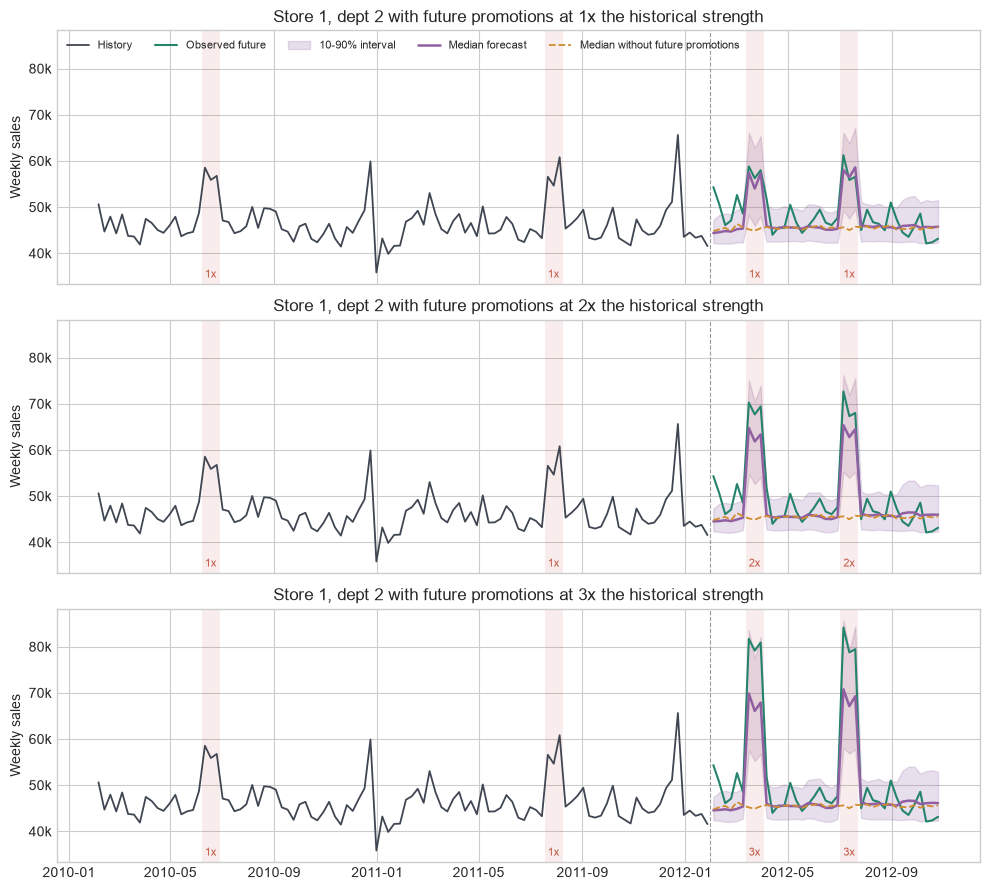

In [13]:
PROMO_ID = "1_2"
PAST_PROMOTIONS = [(18, 21), (76, 79)]  # Week indices; chosen away from holiday weeks.
FUTURE_PROMOTIONS = [(HISTORY + 6, HISTORY + 9), (HISTORY + 22, HISTORY + 25)]
PROMOTION_STRENGTHS = [1.0, 2.0, 3.0]
PROMOTION_COLOR = "#c25645"

promo_base = series(PROMO_ID)
PROMOTION_UPLIFT = 0.25 * promo_base[:HISTORY].mean()

def make_promotion(future_strength, past_strength=1.0):
    promotion = np.zeros(SERIES_LENGTH, dtype=np.float32)
    for start, end in PAST_PROMOTIONS:
        promotion[start:end] = past_strength
    for start, end in FUTURE_PROMOTIONS:
        promotion[start:end] = future_strength
    return promotion

def make_promotion_input(target, promotion):
    return {
        "target": target[:HISTORY],
        "past_covariates": {"promotion": promotion[:HISTORY]},
        "future_covariates": {"promotion": promotion[HISTORY:]},
    }

def shade_promotions(ax, promotion):
    for start, end in PAST_PROMOTIONS + FUTURE_PROMOTIONS:
        left, right = dates[start] - HALF_WEEK, dates[end - 1] + HALF_WEEK
        ax.axvspan(left, right, color=PROMOTION_COLOR, alpha=0.10, lw=0)
        ax.annotate(f"{promotion[start]:g}x", (left + (right - left) / 2, 0.0), xycoords=("data", "axes fraction"),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8, color=PROMOTION_COLOR)

scenario_strengths = [0.0] + PROMOTION_STRENGTHS
scenario_promotions = [make_promotion(future_strength=strength) for strength in scenario_strengths]
scenario_targets = [promo_base + PROMOTION_UPLIFT * promotion for promotion in scenario_promotions]
scenario_quantiles = predict([make_promotion_input(target, promotion) for target, promotion in zip(scenario_targets, scenario_promotions)])
baseline_median = scenario_quantiles[0][:, 1]  # 0x scenario: no future promotions.

fig, axes = plt.subplots(len(PROMOTION_STRENGTHS), 1, figsize=(10, 3.0 * len(PROMOTION_STRENGTHS)), sharex=True, sharey=True)
for ax, strength, target, promotion, quantiles in zip(axes, scenario_strengths[1:], scenario_targets[1:], scenario_promotions[1:], scenario_quantiles[1:]):
    plot_forecast(ax, target[:HISTORY], target[HISTORY:], quantiles,
                  f"{describe(PROMO_ID)} with future promotions at {strength:g}x the historical strength",
                  reference=baseline_median, reference_label="Median without future promotions")
    shade_promotions(ax, promotion)
    for start, end in FUTURE_PROMOTIONS:
        window = slice(start - HISTORY, end - HISTORY)
        predicted_uplift = (quantiles[window, 1] - baseline_median[window]).mean()
        print(f"{strength:g}x promotion from {dates[start].date()}: true uplift {PROMOTION_UPLIFT * strength / 1000:5.1f}k, "
              f"predicted uplift {predicted_uplift / 1000:5.1f}k")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "03_promotion_scenarios")
plt.show()

### 3c. Dose–response curve ▶ new

The standard way to show promotion elasticity: planned strength on the x-axis, predicted uplift on the y-axis, the true (simulated) uplift as the 45° reference. One panel, one message: the model interpolates (≤ 1x) and extrapolates conservatively (> 1x).

          true uplift ($k)  predicted uplift ($k)  predicted / true
strength                                                           
0.5               5.720000                   7.58              1.32
1.0              11.450000                  11.67              1.02
1.5              17.170000                  15.45              0.90
2.0              22.900000                  18.46              0.81
2.5              28.620001                  20.97              0.73
3.0              34.349998                  23.18              0.67


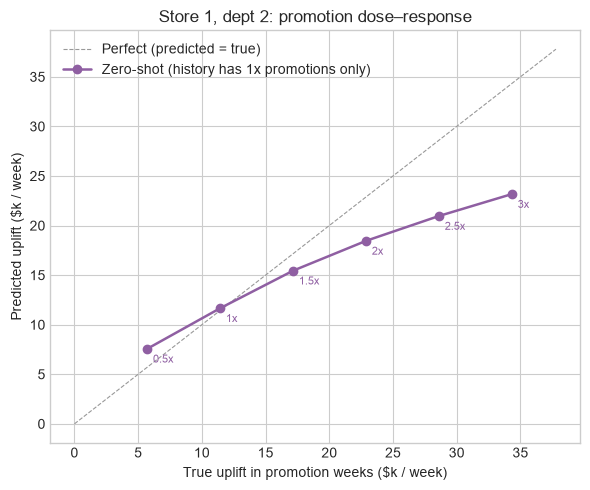

In [14]:
DOSE_STRENGTHS = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]

def predicted_uplift(quantiles, baseline_median):
    windows = [slice(start - HISTORY, end - HISTORY) for start, end in FUTURE_PROMOTIONS]
    return float(np.mean([(quantiles[w, 1] - baseline_median[w]).mean() for w in windows]))

dose_promotions = [make_promotion(future_strength=s) for s in [0.0] + DOSE_STRENGTHS]
dose_targets = [promo_base + PROMOTION_UPLIFT * p for p in dose_promotions]
dose_quantiles = predict([make_promotion_input(t, p) for t, p in zip(dose_targets, dose_promotions)])
dose_baseline = dose_quantiles[0][:, 1]
dose_table = pd.DataFrame({
    "strength": DOSE_STRENGTHS,
    "true uplift ($k)": [PROMOTION_UPLIFT * s / 1000 for s in DOSE_STRENGTHS],
    "predicted uplift ($k)": [predicted_uplift(q, dose_baseline) / 1000 for q in dose_quantiles[1:]],
}).set_index("strength")
dose_table["predicted / true"] = dose_table["predicted uplift ($k)"] / dose_table["true uplift ($k)"]
print(dose_table.round(2).to_string())

def plot_dose_response(ax, table, column, label, color):
    ax.plot(table["true uplift ($k)"], table[column], "o-", color=color, lw=1.8, label=label)
    for s, row in table.iterrows():
        ax.annotate(f"{s:g}x", (row["true uplift ($k)"], row[column]), xytext=(4, -10), textcoords="offset points", fontsize=8, color=color)

fig, ax = plt.subplots(figsize=(6, 5))
lim = dose_table["true uplift ($k)"].max() * 1.1
ax.plot([0, lim], [0, lim], color="#999999", lw=0.8, ls="--", label="Perfect (predicted = true)")
plot_dose_response(ax, dose_table, "predicted uplift ($k)", "Zero-shot (history has 1x promotions only)", COLORS["forecast"])
ax.set_xlabel("True uplift in promotion weeks ($k / week)")
ax.set_ylabel("Predicted uplift ($k / week)")
ax.set_title(f"{describe(PROMO_ID)}: promotion dose–response")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
savefig(fig, "03_dose_response")
plt.show()

## 4. Forecasting with examples

This is the capability that sets iAmTime apart. The full ICL input supplies completed **support examples** before the query. Each example has a target history and its observed future (and, optionally, covariates for both); the model treats them as demonstrations of how series like the query behave and infers the task from them — no fine-tuning, one forward pass.

**Input card.**

```python
{
    "example_target_histories": [hist_1, ..., hist_k],   # each (L_e,)   completed demonstrations
    "example_target_futures":   [fut_1,  ..., fut_k],    # each (H,)
    "query_target_history":     hist_q,                  # (L_q,)       the series to forecast
}
```

Examples must end **before** the query's forecast origin (no leakage). This section builds them from the past of the query and of similar series, one year before the query's horizon, and answers four questions:

| § | Question | Format |
|---|---|---|
| 4a–4d | How do I pick similar series? | cluster neighbours vs. season-matched neighbours |
| 4b′ | What does the model actually see? | prompt-anatomy figure |
| 4e–4f | Do examples help, and which ones? | scorecard on 512 series + relevance ladder with a shuffled-futures **control** |
| 4g | How does the error change with the number of examples? | k-shot curve, k = 0 to 12 |
| 4h | What is the business case? | cold start: a 12-week-old series with examples from sibling stores |
| 4i | Can examples teach a rule the history does not contain? | promotion elasticity at 2x/3x, via examples with covariates |

Throughout, the query uses its **full 104-week history**, and the reference is zero-shot forecasting from that same history. Examples are aligned with the query's season one year earlier; because the data starts in February 2010, each example has 52 weeks of history and a 39-week future. The exception is the cold-start case in 4h, where the query by design has only 12 weeks.

### 4a. Clustering Walmart series

Each series' 104-week history is z-normalised (so clusters reflect shape, not sales volume) and grouped with k-means into 8 clusters. Only the history is used, so nothing from the forecast window leaks into the choice of examples. The plot shows each cluster's mean normalised profile, and the printout lists the most common departments per cluster: similar departments in different stores tend to land together.

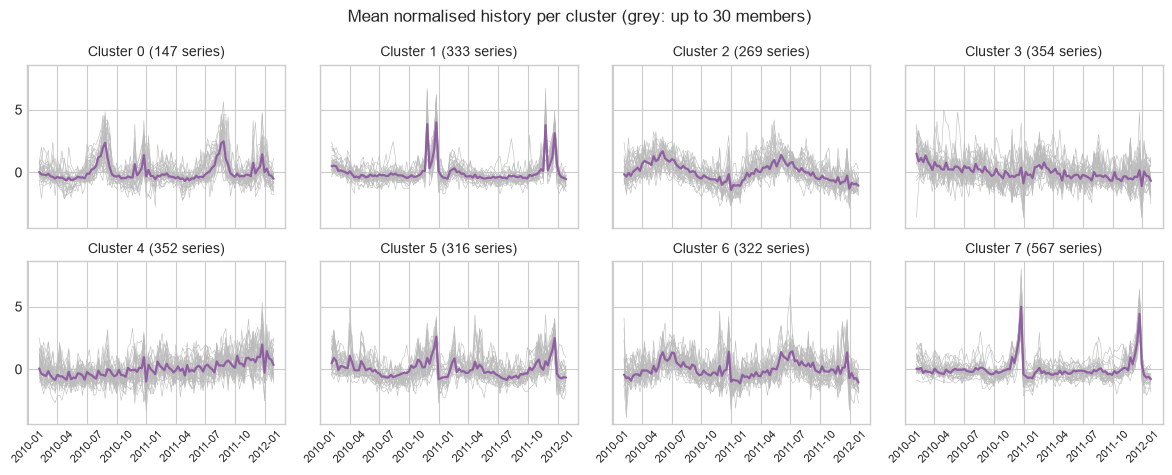

Cluster 0: most common departments 3 (45), 74 (26), 31 (25), 24 (12)
Cluster 1: most common departments 14 (38), 55 (37), 72 (37), 5 (37)
Cluster 2: most common departments 16 (43), 12 (33), 30 (28), 56 (26)
Cluster 3: most common departments 83 (35), 79 (35), 13 (25), 49 (23)
Cluster 4: most common departments 92 (32), 90 (31), 38 (27), 87 (27)
Cluster 5: most common departments 1 (44), 67 (44), 28 (39), 26 (32)
Cluster 6: most common departments 36 (30), 11 (30), 9 (29), 95 (29)
Cluster 7: most common departments 82 (43), 7 (37), 32 (37), 23 (36)


In [15]:
NUM_CLUSTERS = 8

cluster_ids = np.asarray(complete_ids)
cluster_targets = np.stack([series(item_id) for item_id in cluster_ids])
cluster_histories = cluster_targets[:, :HISTORY]
cluster_std = cluster_histories.std(axis=1, keepdims=True)
keep = cluster_std[:, 0] > 0
cluster_ids, cluster_targets, cluster_histories, cluster_std = cluster_ids[keep], cluster_targets[keep], cluster_histories[keep], cluster_std[keep]
normalized_histories = (cluster_histories - cluster_histories.mean(axis=1, keepdims=True)) / cluster_std

kmeans = KMeans(n_clusters=NUM_CLUSTERS, n_init=10, random_state=0).fit(normalized_histories)
cluster_labels = kmeans.labels_

fig, axes = plt.subplots(2, NUM_CLUSTERS // 2, figsize=(12, 4.8), sharex=True, sharey=True)
for cluster, ax in enumerate(axes.ravel()):
    members = cluster_labels == cluster
    ax.plot(history_dates, normalized_histories[members].T[:, :30], color="#bbbbbb", lw=0.4)
    ax.plot(history_dates, kmeans.cluster_centers_[cluster], color=COLORS["forecast"], lw=1.6)
    ax.set_title(f"Cluster {cluster} ({members.sum()} series)", fontsize=10)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
fig.suptitle("Mean normalised history per cluster (grey: up to 30 members)", fontsize=12)
plt.tight_layout()
savefig(fig, "04a_clusters")
plt.show()

departments = pd.Series([item_id.split("_")[1] for item_id in cluster_ids])
for cluster in range(NUM_CLUSTERS):
    top = departments[cluster_labels == cluster].value_counts().head(4)
    print(f"Cluster {cluster}: most common departments " + ", ".join(f"{dept} ({count})" for dept, count in top.items()))

### 4b. Examples from the query and its cluster neighbours

The query is department 3 of store 4, which has a strong late-summer peak. Its full 104-week history already shows that peak twice, so the forecasts with and without examples are close (MASE in the title); Section 4e shows the typical effect over many series.

The query uses its full 104-week history. The examples are built only from data before the forecast start:

- **Example history**: the 52 weeks from 2010-02-05 to 2011-01-28.
- **Example future**: the following 39 weeks (2011-02-04 to 2011-10-28), the same calendar window as the query's horizon one year earlier.
- **Sources**: the query itself plus its `NUM_NEIGHBOURS = 4` nearest neighbours (Euclidean distance between normalised histories) in its cluster, so 5 examples in total. The model was trained with up to 6 examples.

Query 4_3 is in cluster 0; neighbours: 41_3, 39_3, 32_3, 11_3


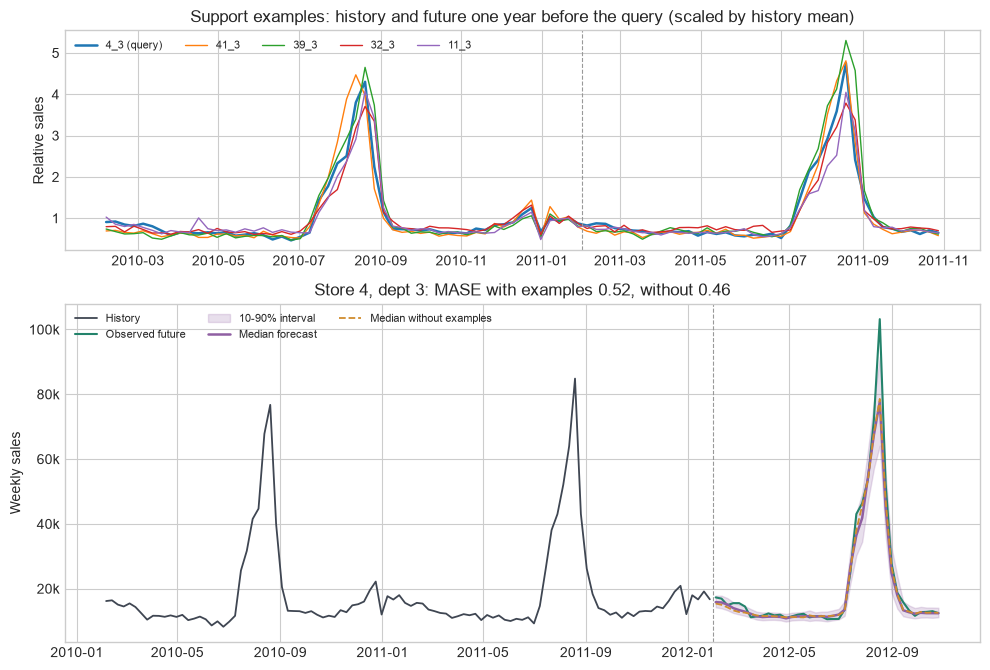

In [16]:
QUERY_ID = "4_3"
QUERY_CONTEXT = HISTORY  # The query uses its full 104-week history.
NUM_NEIGHBOURS = 4
SEASON = 52
# Examples sit one year before the query's horizon. The data starts in February 2010,
# so an example can have at most HISTORY - SEASON = 52 weeks of history.
EXAMPLE_HISTORY = slice(0, HISTORY - SEASON)
EXAMPLE_FUTURE = slice(HISTORY - SEASON, HISTORY - SEASON + HORIZON)
EXAMPLE_CONTEXT = EXAMPLE_HISTORY.stop - EXAMPLE_HISTORY.start

def nearest_neighbours(index, count):
    candidates = np.flatnonzero((cluster_labels == cluster_labels[index]) & (np.arange(len(cluster_ids)) != index))
    distances = np.linalg.norm(normalized_histories[candidates] - normalized_histories[index], axis=1)
    return candidates[np.argsort(distances)[:count]]

def make_example_input(index, source_indices):
    return {
        "example_target_histories": [cluster_targets[source, EXAMPLE_HISTORY] for source in source_indices],
        "example_target_futures": [cluster_targets[source, EXAMPLE_FUTURE] for source in source_indices],
        "query_target_history": cluster_targets[index, HISTORY - QUERY_CONTEXT:HISTORY],
    }

query_index = int(np.flatnonzero(cluster_ids == QUERY_ID)[0])
neighbour_indices = nearest_neighbours(query_index, NUM_NEIGHBOURS)
example_sources = [query_index, *neighbour_indices]
print(f"Query {QUERY_ID} is in cluster {cluster_labels[query_index]}; neighbours: {', '.join(cluster_ids[neighbour_indices])}")

query_values = cluster_targets[query_index]
example_quantiles = predict([make_example_input(query_index, example_sources)])[0]
short_quantiles = predict(query_values[None, HISTORY - QUERY_CONTEXT:HISTORY])[0]  # Same context, no examples.
example_score = mase(query_values[:HISTORY], query_values[HISTORY:], example_quantiles[:, 1])
short_score = mase(query_values[:HISTORY], query_values[HISTORY:], short_quantiles[:, 1])

fig, axes = plt.subplots(2, 1, figsize=(10, 6.8), gridspec_kw={"height_ratios": [1.3, 2.0]})
for source in example_sources:
    window = cluster_targets[source, EXAMPLE_HISTORY.start:EXAMPLE_FUTURE.stop]
    label = f"{cluster_ids[source]} (query)" if source == query_index else cluster_ids[source]
    axes[0].plot(dates[EXAMPLE_HISTORY.start:EXAMPLE_FUTURE.stop], window / window[:EXAMPLE_CONTEXT].mean(),
                 lw=1.8 if source == query_index else 1.0, label=label)
axes[0].axvline(dates[EXAMPLE_FUTURE.start] - HALF_WEEK, color="#999999", lw=0.8, ls="--")
axes[0].set_title("Support examples: history and future one year before the query (scaled by history mean)")
axes[0].set_ylabel("Relative sales")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)

plot_forecast(axes[1], query_values[HISTORY - QUERY_CONTEXT:HISTORY], query_values[HISTORY:], example_quantiles,
              f"{describe(QUERY_ID)}: MASE with examples {example_score:.2f}, without {short_score:.2f}",
              reference=short_quantiles[:, 1], reference_label="Median without examples")
axes[1].legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "04b_cluster_examples")
plt.show()

### 4b′. Prompt anatomy: what the model actually sees ▶ new

The same input as 4b, drawn the way the model receives it. Each row is one block of the prompt: five completed examples (history → observed future, one year before the query), then the query (history → **?**). The x-axis is weeks from each block's forecast origin, so the examples' Feb–Oct 2011 and the query's Feb–Oct 2012 line up. Example histories are 52 weeks long and the query's history is 104 weeks; one prompt can mix lengths. The model answers the **?** by applying what the examples demonstrate.

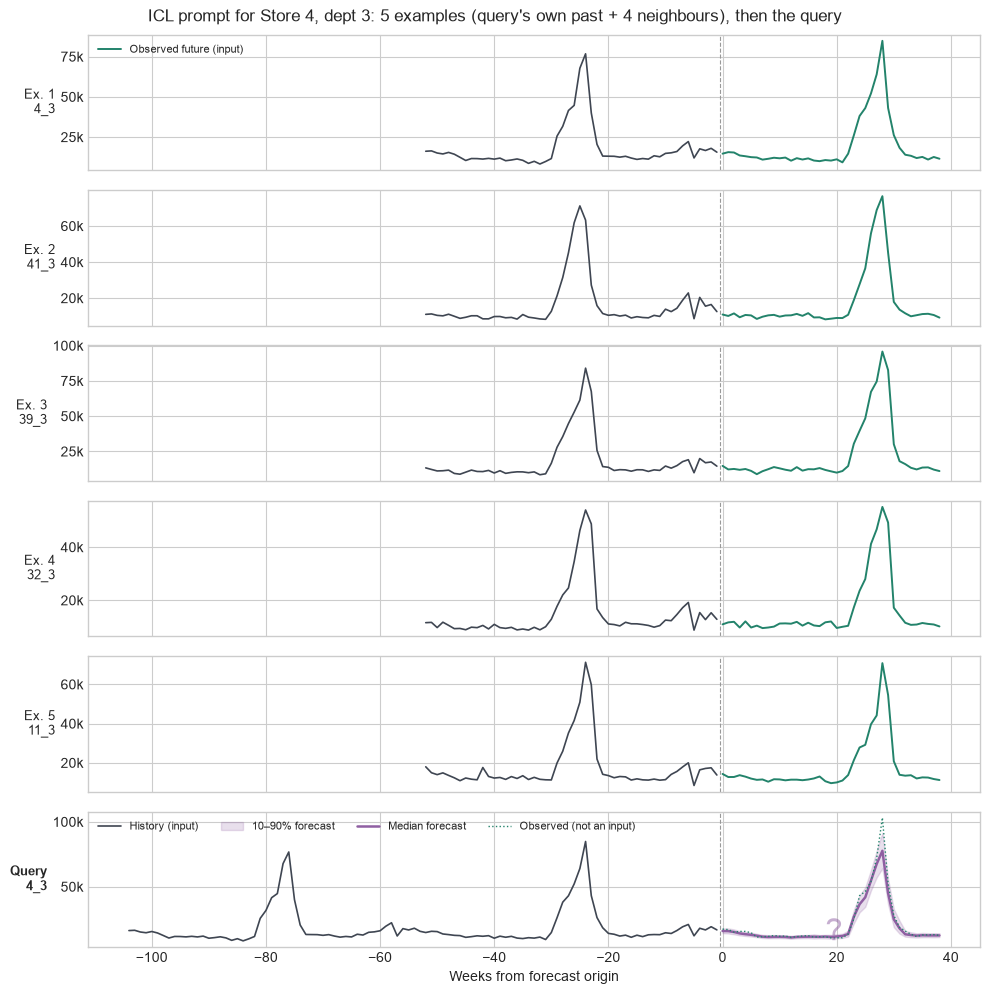

In [17]:
def plot_prompt_anatomy(example_sources, query_index, query_context, quantiles, title, name=None, example_history=EXAMPLE_HISTORY):
    weeks_fut = np.arange(0, HORIZON)
    rows = len(example_sources) + 1
    fig, axes = plt.subplots(rows, 1, figsize=(10, 1.55 * rows + 0.8), sharex=True)
    for ax, source in zip(axes, example_sources):
        hist = cluster_targets[source, example_history]
        fut = cluster_targets[source, EXAMPLE_FUTURE]
        ax.plot(np.arange(-len(hist), 0), hist, color=COLORS["history"], lw=1.2)
        ax.plot(weeks_fut, fut, color=COLORS["truth"], lw=1.4)
        ax.set_ylabel(f"Ex. {example_sources.index(source) + 1}\n{cluster_ids[source]}", rotation=0, ha="right", va="center", fontsize=9)
        ax.yaxis.set_major_formatter(sales_formatter)
    ax = axes[-1]
    q_hist = cluster_targets[query_index, HISTORY - query_context:HISTORY]
    ax.plot(np.arange(-query_context, 0), q_hist, color=COLORS["history"], lw=1.2, label="History (input)")
    ax.fill_between(weeks_fut, quantiles[:, 0], quantiles[:, 2], color=COLORS["forecast"], alpha=0.2, label="10–90% forecast")
    ax.plot(weeks_fut, quantiles[:, 1], color=COLORS["forecast"], lw=1.8, label="Median forecast")
    ax.plot(weeks_fut, cluster_targets[query_index, HISTORY:], color=COLORS["truth"], lw=1.0, ls=":", label="Observed (not an input)")
    ax.set_ylabel(f"Query\n{cluster_ids[query_index]}", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    ax.yaxis.set_major_formatter(sales_formatter)
    ax.text(HORIZON / 2, 0.05, "?", transform=ax.get_xaxis_transform(), ha="center", fontsize=22, color=COLORS["forecast"], alpha=0.5)
    ax.legend(ncol=4, frameon=False, loc="upper left", fontsize=8)
    ax.set_xlabel("Weeks from forecast origin")
    for ax in axes:
        ax.axvline(-0.5, color="#999999", lw=0.8, ls="--")
    axes[0].plot([], [], color=COLORS["truth"], lw=1.4, label="Observed future (input)")
    axes[0].legend(frameon=False, loc="upper left", fontsize=8)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if name:
        savefig(fig, name)
    plt.show()

plot_prompt_anatomy(example_sources, query_index, QUERY_CONTEXT, example_quantiles,
                    f"ICL prompt for {describe(QUERY_ID)}: 5 examples (query's own past + 4 neighbours), then the query",
                    name="04b_prompt_anatomy")

### 4c. Choosing neighbours by matching the season of interest

Clustering compares whole two-year histories, but the forecast only covers February to October. A more targeted choice compares series only over the **season of interest**: the same calendar window one year earlier (2011-02-04 to 2011-10-28), which is exactly the window used as the example future.

Each series is z-normalised over that window, and the query's neighbours are the `NUM_NEIGHBOURS = 4` series with the smallest Euclidean distance to it, from any cluster. As before, only data from before the forecast start is used.

For the department 3 query of 4b, both methods pick the same four department 3 series, so this section uses a different query: department 34 of store 2 (`SEASON_QUERY_ID = "2_34"`). It was picked because its season-matched and cluster neighbours differ (they share one series). Section 4e shows the typical effect. The plot compares the query with both sets of neighbours over the matching window.

Query 2_34 is in cluster 2
Season-matched neighbours: 31_34 (cluster 2), 13_46 (cluster 7), 21_34 (cluster 5), 41_46 (cluster 7)
Cluster neighbours: 6_34 (cluster 2), 31_34 (cluster 2), 6_25 (cluster 2), 15_34 (cluster 2)


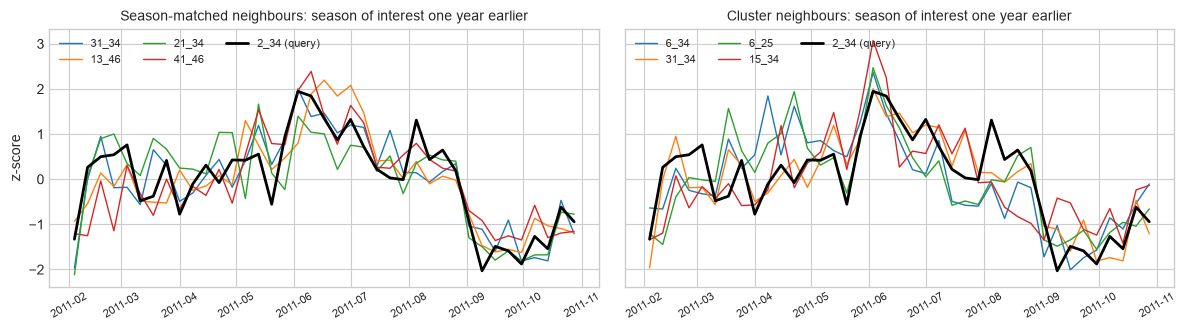

In [18]:
SEASON_QUERY_ID = "2_34"
SEASON_WINDOW = EXAMPLE_FUTURE  # Last year's version of the forecast window.
season_profiles = cluster_targets[:, SEASON_WINDOW]
season_profiles = (season_profiles - season_profiles.mean(axis=1, keepdims=True)) / season_profiles.std(axis=1, keepdims=True).clip(min=1e-6)

def season_neighbours(index, count):
    distances = np.linalg.norm(season_profiles - season_profiles[index], axis=1)
    distances[index] = np.inf
    return np.argsort(distances)[:count]

season_query_index = int(np.flatnonzero(cluster_ids == SEASON_QUERY_ID)[0])
season_indices = season_neighbours(season_query_index, NUM_NEIGHBOURS)
season_cluster_indices = nearest_neighbours(season_query_index, NUM_NEIGHBOURS)
print(f"Query {SEASON_QUERY_ID} is in cluster {cluster_labels[season_query_index]}")
for name, indices in [("Season-matched", season_indices), ("Cluster", season_cluster_indices)]:
    print(f"{name} neighbours: " + ", ".join(f"{cluster_ids[i]} (cluster {cluster_labels[i]})" for i in indices))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, (name, indices) in zip(axes, [("Season-matched neighbours", season_indices), ("Cluster neighbours", season_cluster_indices)]):
    for index in indices:
        ax.plot(dates[SEASON_WINDOW], season_profiles[index], lw=1.0, label=cluster_ids[index])
    ax.plot(dates[SEASON_WINDOW], season_profiles[season_query_index], color="black", lw=2.0, label=f"{SEASON_QUERY_ID} (query)")
    ax.set_title(f"{name}: season of interest one year earlier", fontsize=10)
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
    ax.legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
axes[0].set_ylabel("z-score")
plt.tight_layout()
savefig(fig, "04c_season_neighbours")
plt.show()

### 4d. Examples from the query and its season-matched neighbours

The examples are built exactly as in 4b (52-week history, 39-week future one year before the query's horizon), only the 4 neighbours change. The query again uses its full 104-week history. For this query the three forecasts are close: season-matched examples are slightly better than no examples and cluster examples slightly worse (MASE in the title). The dashed line is the forecast without examples and the dotted line the forecast with cluster-based examples built as in 4b.

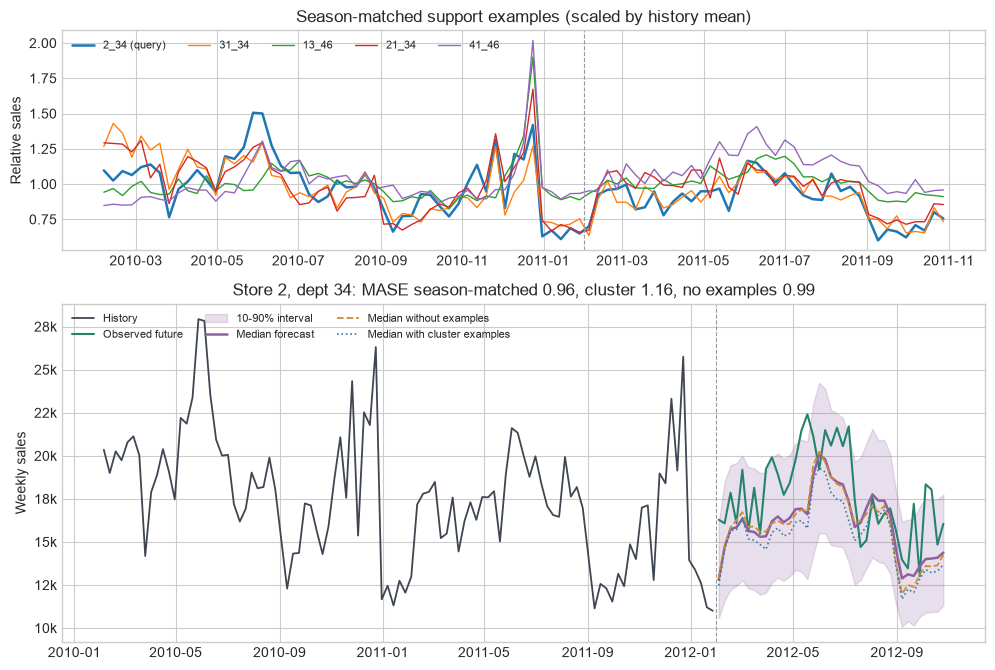

In [19]:
season_values = cluster_targets[season_query_index]
season_sources = [season_query_index, *season_indices]
season_quantiles, season_cluster_quantiles, season_short_quantiles = predict([
    make_example_input(season_query_index, season_sources),
    make_example_input(season_query_index, [season_query_index, *season_cluster_indices]),
    {"query_target_history": season_values[HISTORY - QUERY_CONTEXT:HISTORY]},  # No examples; same dict format so it can share the batch.
])
season_scores = {
    name: mase(season_values[:HISTORY], season_values[HISTORY:], quantiles[:, 1])
    for name, quantiles in [("season", season_quantiles), ("cluster", season_cluster_quantiles), ("none", season_short_quantiles)]
}

fig, axes = plt.subplots(2, 1, figsize=(10, 6.8), gridspec_kw={"height_ratios": [1.3, 2.0]})
for source in season_sources:
    window = cluster_targets[source, EXAMPLE_HISTORY.start:EXAMPLE_FUTURE.stop]
    label = f"{cluster_ids[source]} (query)" if source == season_query_index else cluster_ids[source]
    axes[0].plot(dates[EXAMPLE_HISTORY.start:EXAMPLE_FUTURE.stop], window / window[:EXAMPLE_CONTEXT].mean(),
                 lw=1.8 if source == season_query_index else 1.0, label=label)
axes[0].axvline(dates[EXAMPLE_FUTURE.start] - HALF_WEEK, color="#999999", lw=0.8, ls="--")
axes[0].set_title("Season-matched support examples (scaled by history mean)")
axes[0].set_ylabel("Relative sales")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)

plot_forecast(axes[1], season_values[HISTORY - QUERY_CONTEXT:HISTORY], season_values[HISTORY:], season_quantiles,
              f"{describe(SEASON_QUERY_ID)}: MASE season-matched {season_scores['season']:.2f}, "
              f"cluster {season_scores['cluster']:.2f}, no examples {season_scores['none']:.2f}",
              reference=season_short_quantiles[:, 1], reference_label="Median without examples")
axes[1].plot(future_dates, season_cluster_quantiles[:, 1], color="#377ca8", lw=1.2, ls=":", label="Median with cluster examples")
axes[1].legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "04d_season_examples")
plt.show()

### 4e. Scorecard: how much do examples help?

The cell below repeats the comparison for `NUM_EVALUATION_SERIES = 512` random series (fixed seed) and six inputs:

- zero-shot with the full 104-week history (the **reference**: the same query context as every ICL variant),
- 104 weeks plus one example from the query's own past,
- 104 weeks plus the query's own example and 4 random series from **other** clusters, to check whether similarity matters,
- 104 weeks plus the query's own example and 4 cluster neighbours (4b),
- 104 weeks plus the query's own example and 4 season-matched neighbours (4d).

In [20]:
NUM_EVALUATION_SERIES = 512  # Set to None to evaluate every series (a few minutes on CPU).

rng = np.random.default_rng(1)
evaluation_indices = (
    np.arange(len(cluster_ids)) if NUM_EVALUATION_SERIES is None
    else rng.choice(len(cluster_ids), size=NUM_EVALUATION_SERIES, replace=False)
)

def random_other_cluster(index, count):
    candidates = np.flatnonzero(cluster_labels != cluster_labels[index])
    return np.random.default_rng(index).choice(candidates, size=count, replace=False)

variants = {
    "zero-shot, 104 weeks": [cluster_targets[i, :HISTORY] for i in evaluation_indices],
    "104 weeks + own example": [make_example_input(i, [i]) for i in evaluation_indices],
    "104 weeks + own + 4 random other-cluster": [
        make_example_input(i, [i, *random_other_cluster(i, NUM_NEIGHBOURS)]) for i in evaluation_indices
    ],
    "104 weeks + own + 4 cluster neighbours": [
        make_example_input(i, [i, *nearest_neighbours(i, NUM_NEIGHBOURS)]) for i in evaluation_indices
    ],
    "104 weeks + own + 4 season-matched neighbours": [
        make_example_input(i, [i, *season_neighbours(i, NUM_NEIGHBOURS)]) for i in evaluation_indices
    ],
}

results = {}
for name, inputs in variants.items():
    quantiles = predict(inputs)
    results[name] = [
        mase(cluster_targets[i, :HISTORY], cluster_targets[i, HISTORY:], q[:, 1])
        for i, q in zip(evaluation_indices, quantiles)
    ]
results = pd.DataFrame(results)
results.agg(["mean", "median"]).T.round(3)

,mean,median
"zero-shot, 104 weeks",0.784,0.709
104 weeks + own example,0.841,0.718
104 weeks + own + 4 random other-cluster,0.816,0.709
104 weeks + own + 4 cluster neighbours,0.824,0.710
104 weeks + own + 4 season-matched neighbours,0.817,0.714


What the comparison shows on this dataset:

- **With a full two-year history, examples do not help on average.** Every example variant has a higher mean MASE than zero-shot from the same history, the medians are within about 0.01 of each other, and the examples win on fewer than half of the series (win rates in 4f). The query's own history already contains the seasonal information that the examples supply.
- **One example from the query's own past is the worst variant.** Adding four more series moves the error back towards zero-shot, and how those four are chosen (random, cluster, season-matched) matters little.
- **Examples pay off when history is missing**: see the cold-start case in 4h.

### 4f. Relevance ladder with a control ▶ new

Two more constructions are added to the same 512 series and the whole comparison is drawn as a bar chart with bootstrap CIs:

- **Sibling examples**: the 4 series of the *same department in other stores* whose season profile is closest to the query's. No clustering needed — the selection is a join on the hierarchy, which is how a business user would describe "similar series".
- **Shuffled-futures control**: the season-matched examples with their futures permuted among the examples (each history is paired with another series' future). The model sees exactly as much data as with the real examples, but the demonstrated history → future mapping is broken. If this control were as good as the real examples, the benefit would be "more context", not in-context learning.

How to read the ladder: bars are mean MASE (lower is better), the grey bar is the reference, the dashed line its value. The paired scorecard beneath it gives win rates and CIs on the differences.

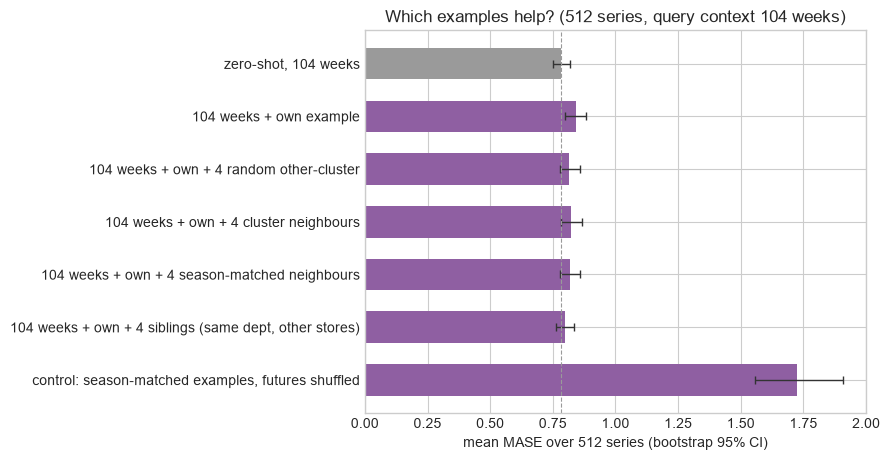

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 104 weeks",,,,,,
"zero-shot, 104 weeks",0.784,"[0.752, 0.817]",0.709,NaN,0.000,"[0.000, 0.000]"
104 weeks + own example,0.841,"[0.798, 0.884]",0.718,0.393,0.057,"[0.033, 0.084]"
104 weeks + own + 4 random other-cluster,0.816,"[0.777, 0.856]",0.709,0.395,0.032,"[0.014, 0.053]"
104 weeks + own + 4 cluster neighbours,0.824,"[0.783, 0.868]",0.710,0.408,0.041,"[0.016, 0.070]"
104 weeks + own + 4 season-matched neighbours,0.817,"[0.778, 0.860]",0.714,0.420,0.033,"[0.014, 0.055]"
"104 weeks + own + 4 siblings (same dept, other stores)",0.797,"[0.762, 0.835]",0.703,0.436,0.014,"[-0.003, 0.031]"
"control: season-matched examples, futures shuffled",1.726,"[1.555, 1.906]",1.055,0.191,0.942,"[0.780, 1.115]"


In [21]:
departments_all = np.array([i.split("_")[1] for i in cluster_ids])

def sibling_neighbours(index, count):
    candidates = np.flatnonzero((departments_all == departments_all[index]) & (np.arange(len(cluster_ids)) != index))
    if len(candidates) == 0:
        return season_neighbours(index, count)
    distances = np.linalg.norm(season_profiles[candidates] - season_profiles[index], axis=1)
    return candidates[np.argsort(distances)[:count]]

def make_shuffled_example_input(index, source_indices):
    # Histories keep their owner; futures are rotated by one position, so no history is paired with its own future.
    rolled = list(np.roll(source_indices, 1))
    return {
        "example_target_histories": [cluster_targets[s, EXAMPLE_HISTORY] for s in source_indices],
        "example_target_futures": [cluster_targets[s, EXAMPLE_FUTURE] for s in rolled],
        "query_target_history": cluster_targets[index, HISTORY - QUERY_CONTEXT:HISTORY],
    }

extra_variants = {
    "104 weeks + own + 4 siblings (same dept, other stores)": [
        make_example_input(i, [i, *sibling_neighbours(i, NUM_NEIGHBOURS)]) for i in evaluation_indices
    ],
    "control: season-matched examples, futures shuffled": [
        make_shuffled_example_input(i, [i, *season_neighbours(i, NUM_NEIGHBOURS)]) for i in evaluation_indices
    ],
}
for name, inputs in extra_variants.items():
    quantiles = predict(inputs)
    results[name] = [
        mase(cluster_targets[i, :HISTORY], cluster_targets[i, HISTORY:], q[:, 1])
        for i, q in zip(evaluation_indices, quantiles)
    ]

REFERENCE = "zero-shot, 104 weeks"
plot_ladder(results, REFERENCE, f"Which examples help? ({len(results)} series, query context 104 weeks)", name="04f_relevance_ladder")
scorecard(results, reference=REFERENCE)

**Result.** Sibling examples (same department, other stores) are the best example variant and statistically indistinguishable from zero-shot: the CI on the difference includes 0. The other example variants are slightly but significantly worse. The **shuffled-futures control is far worse than everything else**, with a mean MASE more than twice the reference: the model does read the history → future pairing in the examples rather than treating them as extra context, so wrong demonstrations actively mislead it.

### 4g. Error vs. number of examples ▶ new

The k-shot curve: the query's own example plus the `k − 1` best season-matched neighbours, for `k = 0, 1, 2, 4, 6, 8, 10, 12`, on 256 of the evaluation series, always with the query's full 104-week history; `k = 0` is zero-shot. The checkpoint was trained with up to 6 examples; the shaded region (`k > 6`) is beyond that, and the model accepts it without changes.

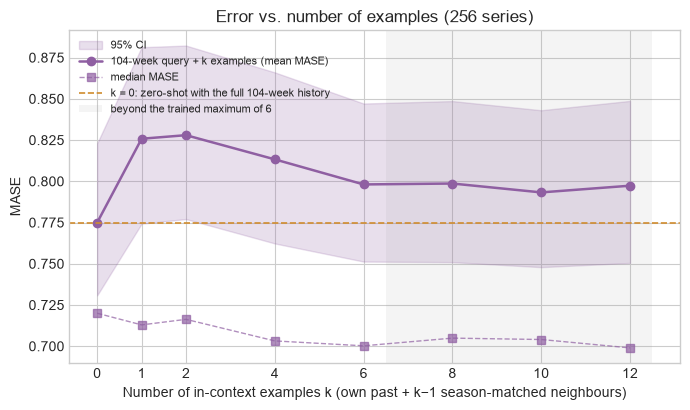

          k=0    k=1    k=2    k=4    k=6    k=8   k=10   k=12
mean    0.775  0.826  0.828  0.813  0.798  0.799  0.793  0.797
median  0.720  0.713  0.716  0.703  0.700  0.705  0.704  0.699


In [22]:
EXAMPLE_COUNTS = [0, 1, 2, 4, 6, 8, 10, 12]
TRAINED_MAX_EXAMPLES = 6  # The checkpoint was trained with up to 6 examples.
curve_indices = evaluation_indices[:256]

def make_k_shot_input(index, k):
    if k == 0:
        return {"query_target_history": cluster_targets[index, HISTORY - QUERY_CONTEXT:HISTORY]}
    return make_example_input(index, [index, *season_neighbours(index, k - 1)])

curve_scores = pd.DataFrame({
    f"k={k}": [
        mase(cluster_targets[i, :HISTORY], cluster_targets[i, HISTORY:], q[:, 1])
        for i, q in zip(curve_indices, predict([make_k_shot_input(i, k) for i in curve_indices]))
    ]
    for k in EXAMPLE_COUNTS
})
rng = np.random.default_rng(0)
idx = rng.integers(0, len(curve_scores), size=(2000, len(curve_scores)))
curve_mean = curve_scores.mean()
curve_ci = np.stack([np.percentile(curve_scores[c].to_numpy()[idx].mean(axis=1), [2.5, 97.5]) for c in curve_scores.columns])
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.fill_between(EXAMPLE_COUNTS, curve_ci[:, 0], curve_ci[:, 1], color=COLORS["forecast"], alpha=0.2, label="95% CI")
ax.plot(EXAMPLE_COUNTS, curve_mean, "o-", color=COLORS["forecast"], lw=1.8, label="104-week query + k examples (mean MASE)")
ax.plot(EXAMPLE_COUNTS, curve_scores.median(), "s--", color=COLORS["forecast"], lw=1.0, alpha=0.7, label="median MASE")
ax.axhline(curve_mean.iloc[0], color=COLORS["reference"], lw=1.2, ls="--", label="k = 0: zero-shot with the full 104-week history")
ax.axvspan(TRAINED_MAX_EXAMPLES + 0.5, EXAMPLE_COUNTS[-1] + 0.5, color="#999999", alpha=0.10, lw=0, label="beyond the trained maximum of 6")
ax.set_xticks(EXAMPLE_COUNTS)
ax.set_xlabel("Number of in-context examples k (own past + k−1 season-matched neighbours)")
ax.set_ylabel("MASE")
ax.set_title(f"Error vs. number of examples ({len(curve_indices)} series)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
savefig(fig, "04g_example_count_curve")
plt.show()
print(pd.DataFrame({"mean": curve_mean, "median": curve_scores.median()}).round(3).T.to_string())

**Result.** With a full history, one or two examples raise the mean error. It falls back as examples are added and is flat from `k = 6` on, staying slightly above zero-shot; the median is at or slightly below zero-shot for every `k`. Going beyond the trained maximum of 6 examples neither helps nor breaks the model. The bootstrap band overlaps the zero-shot line throughout, so none of these differences is large.

### 4h. Cold start: a 12-week-old series with sibling examples ▶ new

The business case for examples. A new department (or a new store) has only `COLD_CONTEXT = 12` weeks of history: too short for any seasonality, and zero-shot forecasting can only extrapolate the level. The same department in other stores has a full year of history, and that is exactly what examples are for.

- **Query**: the last 12 weeks before the forecast origin.
- **Examples**: the 5 sibling series (same department, other stores, closest season profile), each as the matching 12-week history and the following 39-week future **one year earlier**. Example histories are kept the same length as the query's.
- The query's own past is **not** used (a new department does not have one).

The figure uses the same query as 4b; the scorecard repeats the comparison on 128 series. The 104-week zero-shot row shows what a mature series achieves and therefore how much of the gap the examples close.

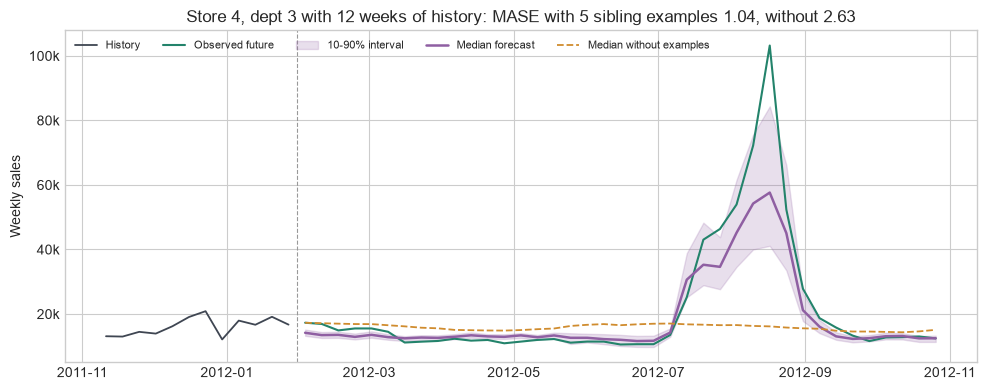

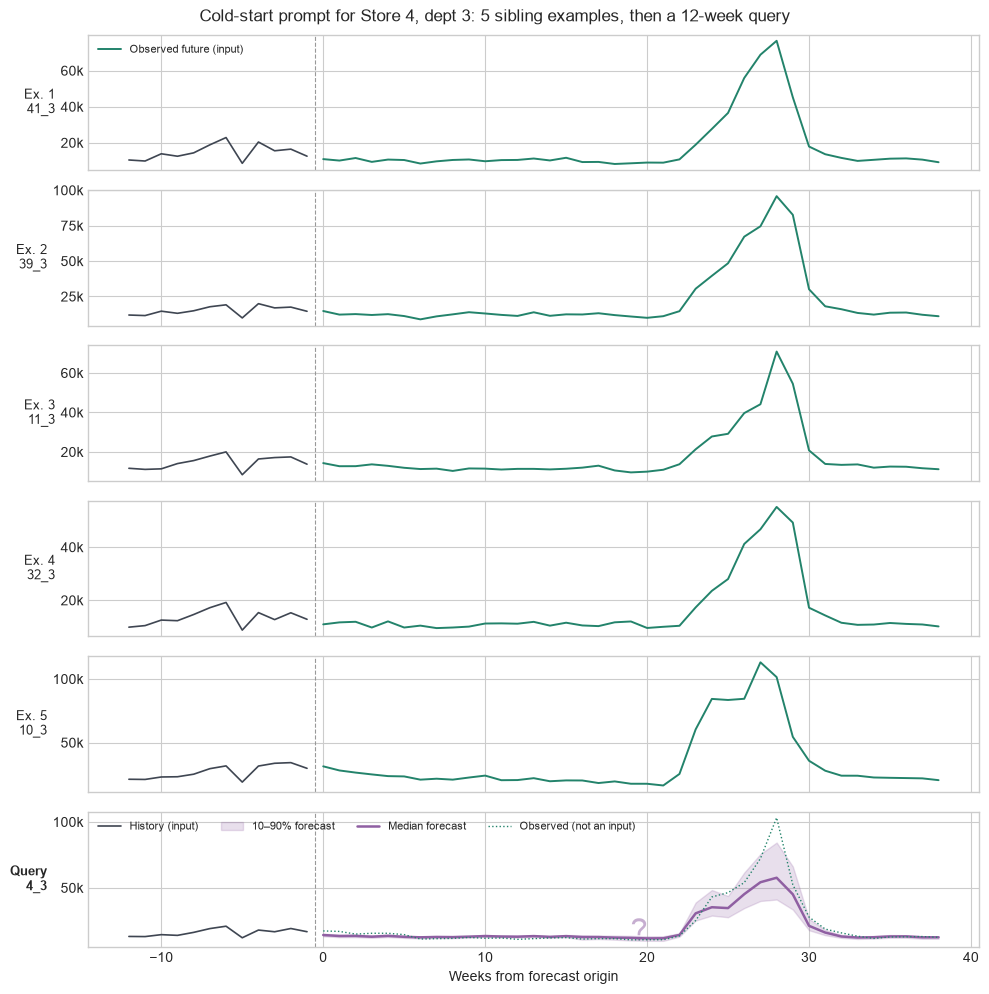

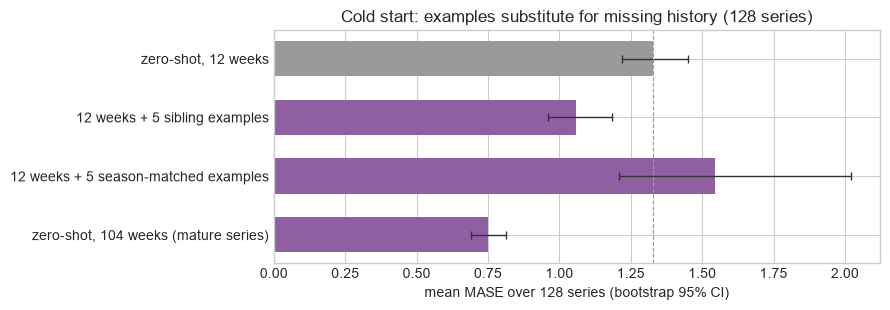

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 12 weeks",,,,,,
"zero-shot, 12 weeks",1.329,"[1.220, 1.451]",1.147,NaN,0.000,"[0.000, 0.000]"
12 weeks + 5 sibling examples,1.059,"[0.959, 1.183]",0.855,0.688,-0.270,"[-0.395, -0.133]"
12 weeks + 5 season-matched examples,1.545,"[1.207, 2.022]",1.035,0.578,0.216,"[-0.106, 0.644]"
"zero-shot, 104 weeks (mature series)",0.751,"[0.692, 0.814]",0.701,0.867,-0.577,"[-0.694, -0.469]"


In [23]:
COLD_CONTEXT = 12
COLD_EXAMPLES = 5
COLD_HISTORY = slice(HISTORY - SEASON - COLD_CONTEXT, HISTORY - SEASON)

def make_cold_input(index, source_indices):
    return {
        "example_target_histories": [cluster_targets[s, COLD_HISTORY] for s in source_indices],
        "example_target_futures": [cluster_targets[s, EXAMPLE_FUTURE] for s in source_indices],
        "query_target_history": cluster_targets[index, HISTORY - COLD_CONTEXT:HISTORY],
    }

cold_sources = list(sibling_neighbours(query_index, COLD_EXAMPLES))
cold_quantiles, cold_zero_quantiles = predict([
    make_cold_input(query_index, cold_sources),
    {"query_target_history": query_values[HISTORY - COLD_CONTEXT:HISTORY]},
])
cold_score = mase(query_values[:HISTORY], query_values[HISTORY:], cold_quantiles[:, 1])
cold_zero_score = mase(query_values[:HISTORY], query_values[HISTORY:], cold_zero_quantiles[:, 1])

fig, ax = plt.subplots(figsize=(10, 4))
plot_forecast(ax, query_values[HISTORY - COLD_CONTEXT:HISTORY], query_values[HISTORY:], cold_quantiles,
              f"{describe(QUERY_ID)} with 12 weeks of history: MASE with 5 sibling examples {cold_score:.2f}, without {cold_zero_score:.2f}",
              reference=cold_zero_quantiles[:, 1], reference_label="Median without examples")
ax.legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "04h_cold_start")
plt.show()
plot_prompt_anatomy(cold_sources, query_index, COLD_CONTEXT, cold_quantiles,
                    f"Cold-start prompt for {describe(QUERY_ID)}: 5 sibling examples, then a 12-week query",
                    name="04h_cold_start_prompt", example_history=COLD_HISTORY)

cold_indices = evaluation_indices[:128]
cold_variants = {
    "zero-shot, 12 weeks": [{"query_target_history": cluster_targets[i, HISTORY - COLD_CONTEXT:HISTORY]} for i in cold_indices],
    "12 weeks + 5 sibling examples": [make_cold_input(i, list(sibling_neighbours(i, COLD_EXAMPLES))) for i in cold_indices],
    "12 weeks + 5 season-matched examples": [make_cold_input(i, list(season_neighbours(i, COLD_EXAMPLES))) for i in cold_indices],
    "zero-shot, 104 weeks (mature series)": [cluster_targets[i, :HISTORY] for i in cold_indices],
}
cold_results = pd.DataFrame({
    name: [mase(cluster_targets[i, :HISTORY], cluster_targets[i, HISTORY:], q[:, 1]) for i, q in zip(cold_indices, predict(inputs))]
    for name, inputs in cold_variants.items()
})
plot_ladder(cold_results, "zero-shot, 12 weeks", f"Cold start: examples substitute for missing history ({len(cold_indices)} series)", name="04h_cold_start_ladder")
scorecard(cold_results, reference="zero-shot, 12 weeks")

**Result.** With only 12 weeks of history, five sibling examples cut the mean MASE from 1.33 to 1.06 and win on about 70 % of series, closing roughly half of the gap to a mature series with 104 weeks of history (0.75). Season-matched examples from arbitrary departments are not reliable here: the median improves but the mean gets worse, driven by a few series where the examples mislead the forecast. For cold start, examples from the same department are the safe choice.

### 4i. Examples that teach a rule: promotion elasticity ▶ new

Section 3c showed the zero-shot model under-predicting 2x and 3x promotions because its history only contains 1x promotions. Examples can carry covariates, so they can **demonstrate the rule** "uplift is proportional to strength" at strengths the query has never experienced.

- **Teachers**: 5 sibling series (department 2 in other stores) with the same synthetic promotion design, built over the example window one year earlier: a 52-week history containing one 1x promotion, and a 39-week future with promotions in the same weeks as the query's (one year earlier) at strengths 1x, 1.5x, 2x, 2.5x and 3x, with the realised linear uplift (25 % of each teacher's own mean sales per unit of strength).
- **Query**: department 2 of store 1 as in 3b/3c, with its full 104-week history (which contains two 1x promotions), and future promotions planned at the dose strengths.
- Predicted uplift is again measured against a 0x scenario forecast with the same examples.

**Input card.** In the ICL format, covariates are arrays with a leading covariate axis, `(num_covariates, length)`, for every example and for the query. They are not named, so row `m` must be the same covariate everywhere:

```python
{
    "example_target_histories": [h_1, ..., h_5],                  # each (52,)
    "example_target_futures":   [f_1, ..., f_5],                  # each (39,)
    "example_exog_histories":   [p_1[None, :52], ..., p_5[None, :52]],    # each (1, 52)
    "example_exog_futures":     [p_1[None, 52:], ..., p_5[None, 52:]],    # each (1, 39)
    "query_target_history":     h_q,                              # (104,)
    "query_exog_history":       p_q[None, :104],                  # (1, 104)
    "query_exog_future":        p_q[None, 104:],                  # (1, 39)
}
```

**How to read the figure.** Same dose–response plot as 3c with a second curve. The closer the "with examples" curve is to the 45° line at 2x–3x, the more of the demonstrated elasticity the model transferred.

Teachers: 10_2 @ 1x, 11_2 @ 1.5x, 12_2 @ 2x, 13_2 @ 2.5x, 14_2 @ 3x


          true uplift ($k)  zero-shot, 104 weeks ($k)  with 5 teaching examples ($k)  zero-shot, 104 weeks / true  with 5 teaching examples / true
strength                                                                                                                                          
0.5               5.720000                       7.58                           9.43                         1.32                             1.65
1.0              11.450000                      11.67                          12.42                         1.02                             1.08
1.5              17.170000                      15.45                          15.92                         0.90                             0.93
2.0              22.900000                      18.46                          19.03                         0.81                             0.83
2.5              28.620001                      20.97                          21.74                         0.73     

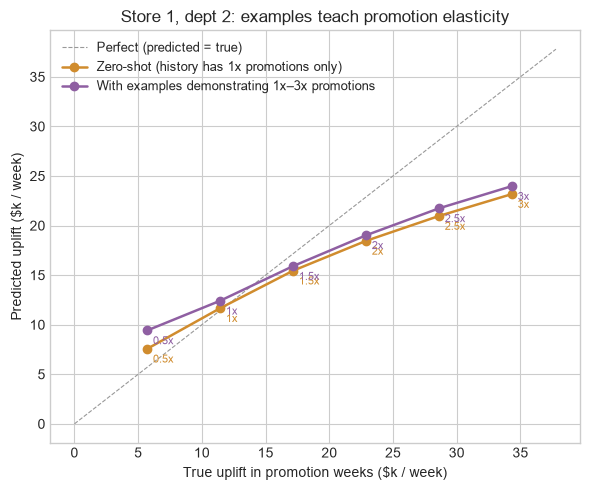

In [24]:
TEACHER_STRENGTHS = [1.0, 1.5, 2.0, 2.5, 3.0]
TEACHER_IDS = [i for i in cluster_ids if i.endswith("_2") and i != PROMO_ID][:len(TEACHER_STRENGTHS)]

def teacher_promotion(future_strength):
    # Over weeks [0, EXAMPLE_FUTURE.stop): the 1x promotions that fall inside the example history,
    # plus the query's future promotion windows shifted one year earlier, at `future_strength`.
    promotion = np.zeros(EXAMPLE_FUTURE.stop, dtype=np.float32)
    for start, end in PAST_PROMOTIONS:
        if end <= EXAMPLE_HISTORY.stop:
            promotion[start:end] = 1.0
    for start, end in FUTURE_PROMOTIONS:
        promotion[start - SEASON:end - SEASON] = future_strength
    return promotion

teacher_examples = []
for item_id, strength in zip(TEACHER_IDS, TEACHER_STRENGTHS):
    base = series(item_id)[:EXAMPLE_FUTURE.stop]
    promotion = teacher_promotion(strength)
    target = base + 0.25 * base[EXAMPLE_HISTORY].mean() * promotion
    teacher_examples.append((target, promotion))
print("Teachers:", ", ".join(f"{i} @ {s:g}x" for i, s in zip(TEACHER_IDS, TEACHER_STRENGTHS)))

def make_icl_promotion_input(target, promotion, examples=None):
    # ICL-format covariates are arrays with a leading covariate axis: (num_covariates, length).
    item = {
        "query_target_history": target[:HISTORY],
        "query_exog_history": promotion[None, :HISTORY],
        "query_exog_future": promotion[None, HISTORY:],
    }
    if examples:
        item["example_target_histories"] = [t[EXAMPLE_HISTORY] for t, _ in examples]
        item["example_target_futures"] = [t[EXAMPLE_FUTURE] for t, _ in examples]
        item["example_exog_histories"] = [p[None, EXAMPLE_HISTORY] for _, p in examples]
        item["example_exog_futures"] = [p[None, EXAMPLE_FUTURE] for _, p in examples]
    return item

zero_quantiles = predict([make_icl_promotion_input(t, p) for t, p in zip(dose_targets, dose_promotions)])
icl_quantiles = predict([make_icl_promotion_input(t, p, teacher_examples) for t, p in zip(dose_targets, dose_promotions)])
elasticity = dose_table[["true uplift ($k)"]].copy()
elasticity["zero-shot, 104 weeks ($k)"] = [predicted_uplift(q, zero_quantiles[0][:, 1]) / 1000 for q in zero_quantiles[1:]]
elasticity["with 5 teaching examples ($k)"] = [predicted_uplift(q, icl_quantiles[0][:, 1]) / 1000 for q in icl_quantiles[1:]]
for column in elasticity.columns[1:]:
    elasticity[column.replace("($k)", "/ true")] = elasticity[column] / elasticity["true uplift ($k)"]
print(elasticity.round(2).to_string())

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, lim], [0, lim], color="#999999", lw=0.8, ls="--", label="Perfect (predicted = true)")
plot_dose_response(ax, elasticity, "zero-shot, 104 weeks ($k)", "Zero-shot (history has 1x promotions only)", COLORS["reference"])
plot_dose_response(ax, elasticity, "with 5 teaching examples ($k)", "With examples demonstrating 1x–3x promotions", COLORS["forecast"])
ax.set_xlabel("True uplift in promotion weeks ($k / week)")
ax.set_ylabel("Predicted uplift ($k / week)")
ax.set_title(f"{describe(PROMO_ID)}: examples teach promotion elasticity")
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.tight_layout()
savefig(fig, "04i_promotion_elasticity")
plt.show()

**Result.** The teaching examples move the curve only slightly towards the 45° line (at 3x, from 67 % to 70 % of the true uplift) and overshoot more at 0.5x. In this setup the model does not pick up the demonstrated elasticity from five examples; it still relies mainly on the 1x promotions in the query's own history.

## Summary

| § | What was shown | Reference | Where the advantage is visible |
|---|---|---|---|
| 1 | Zero-shot fan charts for three behaviours in one batch | seasonal naive | scorecard win rate |
| 2 | Joint forecast of correlated departments | each variate alone | title MASE pairs; 80-triple scorecard says how often it helps |
| 3 | Covariates and promotion what-ifs as batch rows | without covariates / 0x | holiday alignment; dose–response curve |
| 4 | Examples as demonstrations | zero-shot from the same context | cold start (4h); the shuffled control (4f) shows the examples are read. No clear gain with a full history (4e, 4g) or for elasticity transfer (4i) |

## Checkpoint scope

This notebook uses the publicly available forecasting checkpoint. iAmTime also supports imputation, anomaly detection, and classification, but checkpoints for those tasks are not currently published.